In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_descriptor  = pd.read_csv('descriptor_data.csv')
df_descriptor = df_descriptor.drop(['Unnamed: 0', 'index', 'SPS.1'], axis=1)
target_values = pd.read_excel('PI-CW.xlsx')
target_values = target_values['Cut-off wavelength(nm)']

In [2]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

std = MinMaxScaler()
df_descriptor_s = std.fit_transform(df_descriptor)

In [3]:
from sklearn.feature_selection import VarianceThreshold
import pandas as pd

sel = VarianceThreshold(threshold=0.01)
X_sel = sel.fit_transform(df_descriptor_s)
feature_index = sel.get_support()

selected_columns = df_descriptor.columns[feature_index]

X_sel_df = pd.DataFrame(X_sel, columns=selected_columns)

print('number of features after remove redundant ones:', sum(feature_index))

number of features after remove redundant ones: 140


In [4]:
y = target_values

In [43]:
from catboost import CatBoostRegressor
from sklearn.feature_selection import SelectFromModel
import pandas as pd


catb2 = CatBoostRegressor()

catb2.fit(X_sel_df, y, verbose=False)


feature_importances = catb2.get_feature_importance()
threshold = 1  
selected_features = X_sel_df.columns[feature_importances > threshold]

X_selected = X_sel_df[selected_features]
X_selected

,MaxEStateIndex,SPS,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,BCUT2D_MWLOW,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,...,EState_VSA3,VSA_EState8,FractionCSP3,NHOHCount,NumHAcceptors,NumSaturatedHeterocycles,NumSaturatedRings,fr_NH1,fr_bicyclic,fr_para_hydroxylation
0,0.565673,0.095501,0.834789,0.999905,0.598905,0.259437,0.320372,0.231907,0.819759,0.239659,...,0.420861,0.000000,0.068235,0.0,0.000,0.0,0.0,0.0,0.222222,0.000000
1,0.188681,0.075347,0.153965,0.999905,0.000095,0.153965,0.670688,0.727610,0.319122,0.856658,...,0.288254,0.000000,0.000000,0.0,0.000,0.0,0.0,0.0,0.222222,0.000000
2,0.184642,0.071317,0.153974,0.997569,0.002431,0.153974,0.670688,0.727784,0.288798,0.856207,...,0.058674,0.000000,0.000000,0.0,0.125,0.0,0.0,0.0,0.222222,0.000000
3,0.084575,0.019358,0.153983,0.999907,0.000093,0.153983,0.670878,0.786082,0.218737,0.999637,...,0.058674,0.000000,0.000000,0.0,0.125,0.0,0.0,0.0,0.222222,0.000000
4,0.173986,0.088075,0.153971,0.756573,0.243427,0.153971,0.746648,0.760785,0.304515,0.855939,...,0.404771,0.000000,0.000000,1.0,0.250,0.0,0.0,1.0,0.444444,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
618,0.432972,0.087374,0.876279,0.176356,0.823644,0.876279,0.731428,0.629807,0.514142,0.843392,...,0.342713,0.194102,0.105455,0.0,0.500,0.0,0.0,0.0,0.222222,0.333333
619,0.423459,0.078695,0.876279,0.173421,0.826579,0.876279,0.731428,0.629891,0.515450,0.843802,...,0.342713,0.196800,0.105455,0.0,0.375,0.0,0.0,0.0,0.222222,0.333333
620,0.289894,0.084920,0.859516,0.176377,0.823623,0.859516,0.737338,0.600984,0.522808,0.832780,...,0.286850,0.000000,0.056585,0.0,0.375,0.0,0.0,0.0,0.333333,0.000000
621,0.283928,0.085992,0.859516,0.173421,0.826579,0.859516,0.940898,0.601080,0.531147,0.833237,...,0.224266,0.000000,0.058000,0.0,0.375,0.0,0.0,0.0,0.333333,0.000000


In [44]:
X_selected.columns

Index(['MaxEStateIndex', 'SPS', 'MaxPartialCharge', 'MinPartialCharge',
       'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'BCUT2D_MWLOW',
       'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'PEOE_VSA12',
       'PEOE_VSA13', 'SMR_VSA4', 'SMR_VSA5', 'SlogP_VSA4', 'SlogP_VSA6',
       'SlogP_VSA8', 'EState_VSA3', 'VSA_EState8', 'FractionCSP3', 'NHOHCount',
       'NumHAcceptors', 'NumSaturatedHeterocycles', 'NumSaturatedRings',
       'fr_NH1', 'fr_bicyclic', 'fr_para_hydroxylation'],
      dtype='object')

In [5]:
X_selected = df_descriptor[['MaxEStateIndex', 'SPS', 'MaxPartialCharge', 'MinPartialCharge',
       'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'BCUT2D_MWLOW',
       'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'PEOE_VSA12',
       'PEOE_VSA13', 'SMR_VSA4', 'SMR_VSA5', 'SlogP_VSA4', 'SlogP_VSA6',
       'SlogP_VSA8', 'EState_VSA3', 'VSA_EState8', 'FractionCSP3', 'NHOHCount',
       'NumHAcceptors', 'NumSaturatedHeterocycles', 'NumSaturatedRings',
       'fr_NH1', 'fr_bicyclic', 'fr_para_hydroxylation']]
X_selected

,MaxEStateIndex,SPS,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,BCUT2D_MWLOW,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,...,EState_VSA3,VSA_EState8,FractionCSP3,NHOHCount,NumHAcceptors,NumSaturatedHeterocycles,NumSaturatedRings,fr_NH1,fr_bicyclic,fr_para_hydroxylation
0,15.055834,14.190476,0.410722,-0.288137,0.410722,0.288137,9.714010,-2.381857,2.567104,-2.545222,...,40.795197,0.000000,0.058824,1,4,0,0,1,2,0
1,13.659419,13.555556,0.265665,-0.288137,0.288137,0.265665,9.924048,-2.147181,2.350060,-2.287223,...,27.941192,0.000000,0.000000,1,4,0,0,1,2,0
2,13.644457,13.428571,0.265667,-0.288615,0.288615,0.265667,9.924048,-2.147099,2.336913,-2.287411,...,5.687386,0.000000,0.000000,1,5,0,0,1,2,0
3,13.273798,11.791667,0.265669,-0.288136,0.288136,0.265669,9.924162,-2.119500,2.306540,-2.227436,...,5.687386,0.000000,0.000000,1,5,0,0,1,2,0
4,13.604986,13.956522,0.265666,-0.337951,0.337951,0.265666,9.969591,-2.131476,2.343727,-2.287523,...,39.235547,0.000000,0.000000,3,6,0,0,3,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
618,14.564298,13.934426,0.419562,-0.456730,0.456730,0.419562,9.960466,-2.193484,2.434608,-2.292770,...,33.220083,3.403708,0.090909,1,8,0,0,1,2,1
619,14.529059,13.661017,0.419562,-0.457330,0.457330,0.419562,9.960466,-2.193444,2.435175,-2.292598,...,33.220083,3.451017,0.090909,1,7,0,0,1,2,1
620,14.034319,13.857143,0.415991,-0.456725,0.456725,0.415991,9.964010,-2.207129,2.438365,-2.297207,...,27.805092,0.000000,0.048780,1,7,0,0,1,3,0
621,14.012223,13.890909,0.415991,-0.457330,0.457330,0.415991,10.086058,-2.207083,2.441981,-2.297016,...,21.738725,0.000000,0.050000,1,7,0,0,1,3,0


In [46]:
X_selected.to_excel('Feature_importance_catb_27.xlsx', index=False)

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2,random_state=1)

In [8]:
from catboost import CatBoostRegressor

catb = CatBoostRegressor()
catb.fit(X_train, y_train, eval_set=(X_test, y_test), verbose=False)

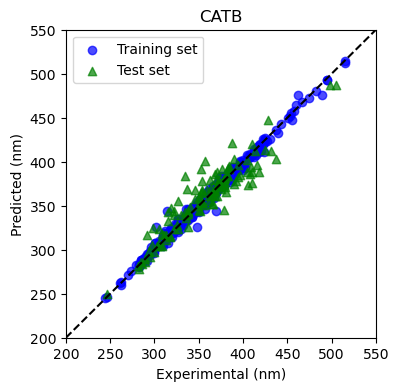

In [49]:
y_train_pred = catb.predict(X_train)
y_test_pred = catb.predict(X_test)

import matplotlib.pyplot as plt

plt.figure(figsize=(4,4))
plt.scatter(y_train, y_train_pred, alpha=0.7, label='Training set', color='blue', marker='o')  # Use different color and marker
plt.scatter(y_test, y_test_pred, alpha=0.7, label='Test set', color='green', marker='^')  # Use different color and marker
plt.plot([200, 550], [200, 550], 'k--')
plt.xlim(200, 550)
plt.ylim(200, 550)
plt.title('CATB')
plt.legend()
plt.xlabel('Experimental (nm)')
plt.ylabel('Predicted (nm)')
plt.show()

In [50]:
from sklearn.metrics import mean_squared_error, r2_score

print('training R = %.3f' % np.sqrt(r2_score(y_train, y_train_pred)))
print('training R2 = %.3f' % r2_score(y_train, y_train_pred))
print('training RMSE = %.3f' % np.sqrt(mean_squared_error(y_train, y_train_pred)))

print('test R = %.3f' % np.sqrt(r2_score(y_test, y_test_pred)))
print('test R2 = %.3f' % r2_score(y_test, y_test_pred))
print('test RMSE = %.3f' % np.sqrt(mean_squared_error(y_test, y_test_pred)))

training R = 0.995
training R2 = 0.990
training RMSE = 4.093
test R = 0.935
test R2 = 0.874
test RMSE = 14.984


In [51]:
# 交叉验证法
from sklearn.model_selection import KFold, cross_val_score

crossvalidation = KFold(n_splits=10, shuffle=True, random_state=1)                        # 分割之前先打乱数据
r2_scores_catb = cross_val_score(catb2, X_selected, y, scoring='r2', cv=crossvalidation)
rmse_scores_catb = cross_val_score(catb2, X_selected,y, scoring='neg_root_mean_squared_error', cv=crossvalidation)
print('Cross-Validation Results:')
print('Folds:%i, mean R: %.3f' %(len(r2_scores_catb), np.sqrt(r2_scores_catb.mean())))
print('Folds:%i, mean R2: %.3f' %(len(r2_scores_catb), r2_scores_catb.mean()))
print('Folds:%i, mean RMSE: %.3f' %(len(rmse_scores_catb), -rmse_scores_catb.mean()))

Learning rate set to 0.037359
0:	learn: 40.8872461	total: 4.17ms	remaining: 4.16s
1:	learn: 40.0576398	total: 7.96ms	remaining: 3.97s
2:	learn: 39.2588439	total: 12.1ms	remaining: 4.02s
3:	learn: 38.5794556	total: 16ms	remaining: 3.99s
4:	learn: 37.8385138	total: 23ms	remaining: 4.58s
5:	learn: 37.1811006	total: 29.4ms	remaining: 4.86s
6:	learn: 36.5406584	total: 32.9ms	remaining: 4.67s
7:	learn: 35.8935974	total: 36.4ms	remaining: 4.51s
8:	learn: 35.2183270	total: 40ms	remaining: 4.4s
9:	learn: 34.6663180	total: 44.3ms	remaining: 4.39s
10:	learn: 34.0968271	total: 48.1ms	remaining: 4.32s
11:	learn: 33.5680791	total: 51.8ms	remaining: 4.27s
12:	learn: 33.0362237	total: 55.3ms	remaining: 4.2s
13:	learn: 32.5113299	total: 59.3ms	remaining: 4.18s
14:	learn: 32.0197897	total: 62.8ms	remaining: 4.12s
15:	learn: 31.5556538	total: 66.2ms	remaining: 4.07s
16:	learn: 31.0771003	total: 69.8ms	remaining: 4.03s
17:	learn: 30.6507897	total: 73.5ms	remaining: 4.01s
18:	learn: 30.2211181	total: 77.3m

179:	learn: 13.3986206	total: 752ms	remaining: 3.43s
180:	learn: 13.3648963	total: 756ms	remaining: 3.42s
181:	learn: 13.3425098	total: 759ms	remaining: 3.41s
182:	learn: 13.3336415	total: 763ms	remaining: 3.4s
183:	learn: 13.3034081	total: 767ms	remaining: 3.4s
184:	learn: 13.2630887	total: 770ms	remaining: 3.39s
185:	learn: 13.2379246	total: 775ms	remaining: 3.39s
186:	learn: 13.1911858	total: 778ms	remaining: 3.38s
187:	learn: 13.1649016	total: 783ms	remaining: 3.38s
188:	learn: 13.1339692	total: 787ms	remaining: 3.38s
189:	learn: 13.1145622	total: 791ms	remaining: 3.37s
190:	learn: 13.0729997	total: 795ms	remaining: 3.37s
191:	learn: 13.0352833	total: 798ms	remaining: 3.36s
192:	learn: 13.0090884	total: 802ms	remaining: 3.35s
193:	learn: 12.9793709	total: 806ms	remaining: 3.35s
194:	learn: 12.9342591	total: 809ms	remaining: 3.34s
195:	learn: 12.8995269	total: 813ms	remaining: 3.33s
196:	learn: 12.8523544	total: 817ms	remaining: 3.33s
197:	learn: 12.8110761	total: 821ms	remaining: 3

375:	learn: 9.3607708	total: 1.54s	remaining: 2.55s
376:	learn: 9.3581283	total: 1.54s	remaining: 2.54s
377:	learn: 9.3510518	total: 1.54s	remaining: 2.54s
378:	learn: 9.3410095	total: 1.55s	remaining: 2.54s
379:	learn: 9.3246794	total: 1.55s	remaining: 2.53s
380:	learn: 9.3198376	total: 1.55s	remaining: 2.53s
381:	learn: 9.2932286	total: 1.56s	remaining: 2.52s
382:	learn: 9.2877676	total: 1.56s	remaining: 2.52s
383:	learn: 9.2678457	total: 1.57s	remaining: 2.52s
384:	learn: 9.2538852	total: 1.57s	remaining: 2.51s
385:	learn: 9.2309685	total: 1.58s	remaining: 2.51s
386:	learn: 9.2133003	total: 1.58s	remaining: 2.5s
387:	learn: 9.2110968	total: 1.58s	remaining: 2.5s
388:	learn: 9.1842772	total: 1.59s	remaining: 2.49s
389:	learn: 9.1588144	total: 1.59s	remaining: 2.49s
390:	learn: 9.1372852	total: 1.59s	remaining: 2.48s
391:	learn: 9.1136137	total: 1.6s	remaining: 2.48s
392:	learn: 9.1074058	total: 1.6s	remaining: 2.48s
393:	learn: 9.1019692	total: 1.61s	remaining: 2.47s
394:	learn: 9.07

569:	learn: 7.3868698	total: 2.32s	remaining: 1.75s
570:	learn: 7.3778998	total: 2.32s	remaining: 1.75s
571:	learn: 7.3673491	total: 2.33s	remaining: 1.74s
572:	learn: 7.3657886	total: 2.33s	remaining: 1.74s
573:	learn: 7.3642512	total: 2.33s	remaining: 1.73s
574:	learn: 7.3528315	total: 2.34s	remaining: 1.73s
575:	learn: 7.3472119	total: 2.34s	remaining: 1.72s
576:	learn: 7.3362270	total: 2.35s	remaining: 1.72s
577:	learn: 7.3355210	total: 2.35s	remaining: 1.72s
578:	learn: 7.3347596	total: 2.35s	remaining: 1.71s
579:	learn: 7.3190693	total: 2.36s	remaining: 1.71s
580:	learn: 7.3129011	total: 2.36s	remaining: 1.7s
581:	learn: 7.3118639	total: 2.37s	remaining: 1.7s
582:	learn: 7.3000948	total: 2.37s	remaining: 1.7s
583:	learn: 7.2858180	total: 2.37s	remaining: 1.69s
584:	learn: 7.2774628	total: 2.38s	remaining: 1.69s
585:	learn: 7.2718082	total: 2.38s	remaining: 1.68s
586:	learn: 7.2612570	total: 2.38s	remaining: 1.68s
587:	learn: 7.2605474	total: 2.39s	remaining: 1.67s
588:	learn: 7.2

764:	learn: 6.0958308	total: 3.1s	remaining: 951ms
765:	learn: 6.0931680	total: 3.1s	remaining: 947ms
766:	learn: 6.0892882	total: 3.1s	remaining: 943ms
767:	learn: 6.0808394	total: 3.11s	remaining: 939ms
768:	learn: 6.0711147	total: 3.11s	remaining: 935ms
769:	learn: 6.0670671	total: 3.12s	remaining: 931ms
770:	learn: 6.0636819	total: 3.12s	remaining: 927ms
771:	learn: 6.0612276	total: 3.12s	remaining: 923ms
772:	learn: 6.0591185	total: 3.13s	remaining: 919ms
773:	learn: 6.0498344	total: 3.13s	remaining: 915ms
774:	learn: 6.0458790	total: 3.14s	remaining: 911ms
775:	learn: 6.0421296	total: 3.14s	remaining: 907ms
776:	learn: 6.0354164	total: 3.14s	remaining: 902ms
777:	learn: 6.0290595	total: 3.15s	remaining: 898ms
778:	learn: 6.0221070	total: 3.15s	remaining: 894ms
779:	learn: 6.0187746	total: 3.15s	remaining: 890ms
780:	learn: 6.0111769	total: 3.16s	remaining: 886ms
781:	learn: 6.0022418	total: 3.16s	remaining: 881ms
782:	learn: 6.0009212	total: 3.17s	remaining: 877ms
783:	learn: 5.9

958:	learn: 5.1026248	total: 3.86s	remaining: 165ms
959:	learn: 5.0962024	total: 3.87s	remaining: 161ms
960:	learn: 5.0908151	total: 3.87s	remaining: 157ms
961:	learn: 5.0820248	total: 3.88s	remaining: 153ms
962:	learn: 5.0784370	total: 3.88s	remaining: 149ms
963:	learn: 5.0735305	total: 3.88s	remaining: 145ms
964:	learn: 5.0695448	total: 3.89s	remaining: 141ms
965:	learn: 5.0654003	total: 3.89s	remaining: 137ms
966:	learn: 5.0645361	total: 3.9s	remaining: 133ms
967:	learn: 5.0618405	total: 3.9s	remaining: 129ms
968:	learn: 5.0570356	total: 3.9s	remaining: 125ms
969:	learn: 5.0565628	total: 3.91s	remaining: 121ms
970:	learn: 5.0519709	total: 3.91s	remaining: 117ms
971:	learn: 5.0493524	total: 3.91s	remaining: 113ms
972:	learn: 5.0471414	total: 3.92s	remaining: 109ms
973:	learn: 5.0457323	total: 3.92s	remaining: 105ms
974:	learn: 5.0436936	total: 3.93s	remaining: 101ms
975:	learn: 5.0405621	total: 3.93s	remaining: 96.7ms
976:	learn: 5.0369565	total: 3.94s	remaining: 92.7ms
977:	learn: 5

... (98 outputs left out)

210:	learn: 12.4724333	total: 849ms	remaining: 3.18s
211:	learn: 12.4577900	total: 853ms	remaining: 3.17s
212:	learn: 12.4502370	total: 857ms	remaining: 3.16s
213:	learn: 12.4409356	total: 860ms	remaining: 3.16s
214:	learn: 12.4082253	total: 864ms	remaining: 3.15s
215:	learn: 12.3981019	total: 869ms	remaining: 3.15s
216:	learn: 12.3514292	total: 872ms	remaining: 3.15s
217:	learn: 12.3458845	total: 876ms	remaining: 3.14s
218:	learn: 12.3026005	total: 880ms	remaining: 3.14s
219:	learn: 12.2785753	total: 884ms	remaining: 3.13s
220:	learn: 12.2731000	total: 888ms	remaining: 3.13s
221:	learn: 12.2487824	total: 892ms	remaining: 3.12s
222:	learn: 12.2135425	total: 896ms	remaining: 3.12s
223:	learn: 12.1747482	total: 900ms	remaining: 3.12s
224:	learn: 12.1361925	total: 904ms	remaining: 3.11s
225:	learn: 12.1253295	total: 908ms	remaining: 3.11s
226:	learn: 12.0892117	total: 912ms	remaining: 3.1s
227:	learn: 12.0747689	total: 916ms	remaining: 3.1s
228:	learn: 12.0369279	total: 920ms	remaining: 3

408:	learn: 8.7600476	total: 1.62s	remaining: 2.35s
409:	learn: 8.7547141	total: 1.63s	remaining: 2.34s
410:	learn: 8.7419060	total: 1.63s	remaining: 2.34s
411:	learn: 8.7203254	total: 1.64s	remaining: 2.33s
412:	learn: 8.7067720	total: 1.64s	remaining: 2.33s
413:	learn: 8.6958001	total: 1.64s	remaining: 2.33s
414:	learn: 8.6942557	total: 1.65s	remaining: 2.32s
415:	learn: 8.6750711	total: 1.65s	remaining: 2.32s
416:	learn: 8.6605966	total: 1.66s	remaining: 2.32s
417:	learn: 8.6574465	total: 1.66s	remaining: 2.31s
418:	learn: 8.6561540	total: 1.67s	remaining: 2.31s
419:	learn: 8.6460116	total: 1.67s	remaining: 2.31s
420:	learn: 8.6272412	total: 1.67s	remaining: 2.3s
421:	learn: 8.6116911	total: 1.68s	remaining: 2.3s
422:	learn: 8.6106627	total: 1.68s	remaining: 2.29s
423:	learn: 8.5963086	total: 1.69s	remaining: 2.29s
424:	learn: 8.5750944	total: 1.69s	remaining: 2.29s
425:	learn: 8.5572024	total: 1.7s	remaining: 2.29s
426:	learn: 8.5432568	total: 1.7s	remaining: 2.29s
427:	learn: 8.53

606:	learn: 6.9119705	total: 2.4s	remaining: 1.56s
607:	learn: 6.9107890	total: 2.41s	remaining: 1.55s
608:	learn: 6.8999328	total: 2.41s	remaining: 1.55s
609:	learn: 6.8958008	total: 2.42s	remaining: 1.54s
610:	learn: 6.8935184	total: 2.42s	remaining: 1.54s
611:	learn: 6.8890654	total: 2.42s	remaining: 1.54s
612:	learn: 6.8793930	total: 2.43s	remaining: 1.53s
613:	learn: 6.8732272	total: 2.44s	remaining: 1.53s
614:	learn: 6.8726772	total: 2.44s	remaining: 1.53s
615:	learn: 6.8604396	total: 2.44s	remaining: 1.52s
616:	learn: 6.8519963	total: 2.45s	remaining: 1.52s
617:	learn: 6.8509243	total: 2.45s	remaining: 1.51s
618:	learn: 6.8412882	total: 2.45s	remaining: 1.51s
619:	learn: 6.8403396	total: 2.46s	remaining: 1.51s
620:	learn: 6.8309572	total: 2.46s	remaining: 1.5s
621:	learn: 6.8279431	total: 2.46s	remaining: 1.5s
622:	learn: 6.8256226	total: 2.47s	remaining: 1.49s
623:	learn: 6.8156772	total: 2.47s	remaining: 1.49s
624:	learn: 6.8010240	total: 2.48s	remaining: 1.49s
625:	learn: 6.7

808:	learn: 5.7952635	total: 3.17s	remaining: 747ms
809:	learn: 5.7904004	total: 3.17s	remaining: 743ms
810:	learn: 5.7879403	total: 3.17s	remaining: 739ms
811:	learn: 5.7842561	total: 3.18s	remaining: 736ms
812:	learn: 5.7753170	total: 3.18s	remaining: 731ms
813:	learn: 5.7711020	total: 3.18s	remaining: 728ms
814:	learn: 5.7665323	total: 3.19s	remaining: 724ms
815:	learn: 5.7634538	total: 3.19s	remaining: 720ms
816:	learn: 5.7629447	total: 3.19s	remaining: 716ms
817:	learn: 5.7616791	total: 3.2s	remaining: 712ms
818:	learn: 5.7522881	total: 3.2s	remaining: 708ms
819:	learn: 5.7466770	total: 3.21s	remaining: 704ms
820:	learn: 5.7400752	total: 3.21s	remaining: 700ms
821:	learn: 5.7341222	total: 3.21s	remaining: 696ms
822:	learn: 5.7297970	total: 3.22s	remaining: 692ms
823:	learn: 5.7224594	total: 3.22s	remaining: 688ms
824:	learn: 5.7190224	total: 3.23s	remaining: 685ms
825:	learn: 5.7127737	total: 3.23s	remaining: 681ms
826:	learn: 5.7111912	total: 3.23s	remaining: 677ms
827:	learn: 5.

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'iterations': range(900, 1200, 100),
    'depth': range(4, 8, 1),
    'learning_rate': np.arange(0.08, 0.13, 0.01),
}


grid_search = GridSearchCV(
    catb2, param_grid=param_grid, scoring='r2', cv=5, verbose=0)
grid_search.fit(X_train, y_train)

print("Best parameters: ", grid_search.best_params_)
print("Best score: ", grid_search.best_score_)

In [25]:
# Best parameters:  {'depth': 4, 'iterations': 900, 'learning_rate': 0.09999999999999999}
# Best score:  0.8145421605102137

In [53]:
best_catb = grid_search.best_estimator_
y_pred = best_catb.predict(X_test)

print('test R = %.3f' % np.sqrt(r2_score(y_test, y_pred)))
print('test R2 = %.3f' % r2_score(y_test, y_pred))
print('test RMSE = %.3f' % np.sqrt(mean_squared_error(y_test, y_pred)))

crossvalidation = KFold(n_splits=10, shuffle=True, random_state=1)                        
r2_scores_catb = cross_val_score(best_catb, X_selected, y, scoring='r2', cv=crossvalidation)
rmse_scores_catb = cross_val_score(best_catb, X_selected,y, scoring='neg_root_mean_squared_error', cv=crossvalidation)
print('Cross-Validation Results:')
print('Folds:%i, mean R: %.3f' %(len(r2_scores_catb), np.sqrt(r2_scores_catb.mean())))
print('Folds:%i, mean R2: %.3f' %(len(r2_scores_catb), r2_scores_catb.mean()))
print('Folds:%i, mean RMSE: %.3f' %(len(rmse_scores_catb), -rmse_scores_catb.mean()))

test R = 0.934
test R2 = 0.872
test RMSE = 15.122
0:	learn: 39.6288213	total: 2.65ms	remaining: 2.39s
1:	learn: 37.6646977	total: 5.12ms	remaining: 2.3s
2:	learn: 36.0109088	total: 6.1ms	remaining: 1.82s
3:	learn: 34.3005491	total: 7.41ms	remaining: 1.66s
4:	learn: 32.9399523	total: 8.81ms	remaining: 1.58s
5:	learn: 31.7115789	total: 10.3ms	remaining: 1.54s
6:	learn: 30.5031497	total: 11.5ms	remaining: 1.47s
7:	learn: 29.4398592	total: 13ms	remaining: 1.45s
8:	learn: 28.5375190	total: 15.1ms	remaining: 1.5s
9:	learn: 27.6713381	total: 16.4ms	remaining: 1.46s
10:	learn: 26.9777456	total: 18.2ms	remaining: 1.47s
11:	learn: 26.3566698	total: 21.2ms	remaining: 1.57s
12:	learn: 25.7394854	total: 23.6ms	remaining: 1.61s
13:	learn: 25.1258480	total: 24.6ms	remaining: 1.56s
14:	learn: 24.6849773	total: 25.7ms	remaining: 1.52s
15:	learn: 24.2699205	total: 27.6ms	remaining: 1.52s
16:	learn: 23.7705797	total: 28.6ms	remaining: 1.48s
17:	learn: 23.3007844	total: 29.6ms	remaining: 1.45s
18:	learn: 

209:	learn: 10.0204230	total: 287ms	remaining: 941ms
210:	learn: 10.0185488	total: 288ms	remaining: 941ms
211:	learn: 10.0145798	total: 290ms	remaining: 940ms
212:	learn: 9.9808589	total: 291ms	remaining: 938ms
213:	learn: 9.9575824	total: 292ms	remaining: 936ms
214:	learn: 9.9441618	total: 293ms	remaining: 935ms
215:	learn: 9.9021053	total: 294ms	remaining: 933ms
216:	learn: 9.8680764	total: 296ms	remaining: 931ms
217:	learn: 9.8370796	total: 297ms	remaining: 929ms
218:	learn: 9.8336321	total: 298ms	remaining: 927ms
219:	learn: 9.8107727	total: 299ms	remaining: 925ms
220:	learn: 9.7900130	total: 301ms	remaining: 924ms
221:	learn: 9.7694568	total: 302ms	remaining: 922ms
222:	learn: 9.7592163	total: 303ms	remaining: 921ms
223:	learn: 9.7217927	total: 304ms	remaining: 918ms
224:	learn: 9.7051266	total: 305ms	remaining: 916ms
225:	learn: 9.6857077	total: 307ms	remaining: 915ms
226:	learn: 9.6461395	total: 308ms	remaining: 913ms
227:	learn: 9.6044780	total: 309ms	remaining: 911ms
228:	lear

484:	learn: 6.2674628	total: 649ms	remaining: 555ms
485:	learn: 6.2584673	total: 651ms	remaining: 555ms
486:	learn: 6.2509101	total: 653ms	remaining: 554ms
487:	learn: 6.2444252	total: 654ms	remaining: 552ms
488:	learn: 6.2298769	total: 655ms	remaining: 551ms
489:	learn: 6.2234118	total: 657ms	remaining: 549ms
490:	learn: 6.2211870	total: 658ms	remaining: 548ms
491:	learn: 6.2115991	total: 659ms	remaining: 546ms
492:	learn: 6.1991462	total: 660ms	remaining: 545ms
493:	learn: 6.1930852	total: 662ms	remaining: 544ms
494:	learn: 6.1818791	total: 663ms	remaining: 542ms
495:	learn: 6.1737526	total: 665ms	remaining: 541ms
496:	learn: 6.1631838	total: 666ms	remaining: 540ms
497:	learn: 6.1593610	total: 668ms	remaining: 539ms
498:	learn: 6.1553346	total: 669ms	remaining: 538ms
499:	learn: 6.1478065	total: 671ms	remaining: 536ms
500:	learn: 6.1471772	total: 672ms	remaining: 535ms
501:	learn: 6.1432742	total: 673ms	remaining: 533ms
502:	learn: 6.1282229	total: 674ms	remaining: 532ms
503:	learn: 

740:	learn: 4.6843155	total: 988ms	remaining: 212ms
741:	learn: 4.6771515	total: 989ms	remaining: 211ms
742:	learn: 4.6764568	total: 991ms	remaining: 209ms
743:	learn: 4.6733009	total: 992ms	remaining: 208ms
744:	learn: 4.6665392	total: 993ms	remaining: 207ms
745:	learn: 4.6649891	total: 994ms	remaining: 205ms
746:	learn: 4.6570248	total: 995ms	remaining: 204ms
747:	learn: 4.6560736	total: 996ms	remaining: 202ms
748:	learn: 4.6554336	total: 998ms	remaining: 201ms
749:	learn: 4.6548654	total: 999ms	remaining: 200ms
750:	learn: 4.6498031	total: 1000ms	remaining: 198ms
751:	learn: 4.6460120	total: 1s	remaining: 197ms
752:	learn: 4.6445222	total: 1s	remaining: 196ms
753:	learn: 4.6411917	total: 1s	remaining: 195ms
754:	learn: 4.6406022	total: 1s	remaining: 193ms
755:	learn: 4.6364447	total: 1.01s	remaining: 192ms
756:	learn: 4.6355280	total: 1.01s	remaining: 190ms
757:	learn: 4.6316160	total: 1.01s	remaining: 189ms
758:	learn: 4.6232978	total: 1.01s	remaining: 188ms
759:	learn: 4.6188805	t

69:	learn: 15.7693105	total: 91.7ms	remaining: 1.09s
70:	learn: 15.6566604	total: 93.5ms	remaining: 1.09s
71:	learn: 15.6362923	total: 94.9ms	remaining: 1.09s
72:	learn: 15.5582636	total: 95.8ms	remaining: 1.08s
73:	learn: 15.4494223	total: 96.8ms	remaining: 1.08s
74:	learn: 15.3826896	total: 97.7ms	remaining: 1.07s
75:	learn: 15.3052947	total: 98.7ms	remaining: 1.07s
76:	learn: 15.2056297	total: 100ms	remaining: 1.07s
77:	learn: 15.1296072	total: 101ms	remaining: 1.07s
78:	learn: 15.0745936	total: 102ms	remaining: 1.06s
79:	learn: 14.9875660	total: 104ms	remaining: 1.06s
80:	learn: 14.8801536	total: 105ms	remaining: 1.06s
81:	learn: 14.8368180	total: 106ms	remaining: 1.06s
82:	learn: 14.7632032	total: 107ms	remaining: 1.05s
83:	learn: 14.7095403	total: 109ms	remaining: 1.05s
84:	learn: 14.6249935	total: 110ms	remaining: 1.05s
85:	learn: 14.5976203	total: 111ms	remaining: 1.05s
86:	learn: 14.5113101	total: 113ms	remaining: 1.06s
87:	learn: 14.4407795	total: 115ms	remaining: 1.06s
88:	l

359:	learn: 7.4458649	total: 443ms	remaining: 665ms
360:	learn: 7.4356246	total: 445ms	remaining: 664ms
361:	learn: 7.4170737	total: 446ms	remaining: 663ms
362:	learn: 7.3928281	total: 447ms	remaining: 661ms
363:	learn: 7.3828923	total: 448ms	remaining: 660ms
364:	learn: 7.3576337	total: 449ms	remaining: 659ms
365:	learn: 7.3400909	total: 450ms	remaining: 657ms
366:	learn: 7.3306504	total: 452ms	remaining: 656ms
367:	learn: 7.3228923	total: 453ms	remaining: 655ms
368:	learn: 7.3203915	total: 454ms	remaining: 653ms
369:	learn: 7.3035597	total: 455ms	remaining: 652ms
370:	learn: 7.2937745	total: 456ms	remaining: 651ms
371:	learn: 7.2926227	total: 458ms	remaining: 650ms
372:	learn: 7.2744494	total: 459ms	remaining: 649ms
373:	learn: 7.2639423	total: 461ms	remaining: 648ms
374:	learn: 7.2467147	total: 462ms	remaining: 647ms
375:	learn: 7.2229338	total: 463ms	remaining: 646ms
376:	learn: 7.2078203	total: 465ms	remaining: 645ms
377:	learn: 7.1976951	total: 467ms	remaining: 645ms
378:	learn: 

... (59 outputs left out)

898:	learn: 4.2251028	total: 1.11s	remaining: 1.24ms
899:	learn: 4.2225571	total: 1.11s	remaining: 0us
0:	learn: 39.0958776	total: 1.5ms	remaining: 1.35s
1:	learn: 37.5185183	total: 2.75ms	remaining: 1.23s
2:	learn: 35.8858462	total: 4.01ms	remaining: 1.2s
3:	learn: 34.1968581	total: 5.8ms	remaining: 1.3s
4:	learn: 32.7494366	total: 7.16ms	remaining: 1.28s
5:	learn: 31.6425092	total: 8.44ms	remaining: 1.26s
6:	learn: 30.4481143	total: 9.58ms	remaining: 1.22s
7:	learn: 29.4077946	total: 10.9ms	remaining: 1.21s
8:	learn: 28.4266078	total: 12ms	remaining: 1.19s
9:	learn: 27.6273149	total: 13.2ms	remaining: 1.18s
10:	learn: 26.9147178	total: 14.5ms	remaining: 1.17s
11:	learn: 26.2848670	total: 15.7ms	remaining: 1.16s
12:	learn: 25.6966563	total: 17ms	remaining: 1.16s
13:	learn: 25.0477337	total: 18.8ms	remaining: 1.19s
14:	learn: 24.6551340	total: 20ms	remaining: 1.18s
15:	learn: 24.2329854	total: 21.4ms	remaining: 1.18s
16:	learn: 23.8268025	total: 22.5ms	remaining: 1.17s
17:	learn: 23.43

245:	learn: 9.4480513	total: 294ms	remaining: 781ms
246:	learn: 9.4271650	total: 295ms	remaining: 781ms
247:	learn: 9.4236213	total: 297ms	remaining: 780ms
248:	learn: 9.3992358	total: 298ms	remaining: 779ms
249:	learn: 9.3717837	total: 299ms	remaining: 778ms
250:	learn: 9.3369206	total: 300ms	remaining: 776ms
251:	learn: 9.3290358	total: 302ms	remaining: 776ms
252:	learn: 9.3103421	total: 303ms	remaining: 775ms
253:	learn: 9.3045067	total: 304ms	remaining: 773ms
254:	learn: 9.2785480	total: 305ms	remaining: 772ms
255:	learn: 9.2527774	total: 307ms	remaining: 771ms
256:	learn: 9.2309439	total: 308ms	remaining: 770ms
257:	learn: 9.2207720	total: 309ms	remaining: 769ms
258:	learn: 9.2176222	total: 310ms	remaining: 768ms
259:	learn: 9.2050798	total: 312ms	remaining: 769ms
260:	learn: 9.2014014	total: 314ms	remaining: 768ms
261:	learn: 9.1886282	total: 315ms	remaining: 766ms
262:	learn: 9.1655215	total: 316ms	remaining: 765ms
263:	learn: 9.1470315	total: 317ms	remaining: 763ms
264:	learn: 

526:	learn: 6.2263688	total: 634ms	remaining: 449ms
527:	learn: 6.2206631	total: 636ms	remaining: 448ms
528:	learn: 6.2164361	total: 637ms	remaining: 447ms
529:	learn: 6.2077329	total: 638ms	remaining: 445ms
530:	learn: 6.2026083	total: 639ms	remaining: 444ms
531:	learn: 6.1920470	total: 641ms	remaining: 443ms
532:	learn: 6.1834237	total: 642ms	remaining: 442ms
533:	learn: 6.1829434	total: 643ms	remaining: 441ms
534:	learn: 6.1769400	total: 645ms	remaining: 440ms
535:	learn: 6.1743847	total: 646ms	remaining: 439ms
536:	learn: 6.1559083	total: 647ms	remaining: 437ms
537:	learn: 6.1551371	total: 648ms	remaining: 436ms
538:	learn: 6.1510773	total: 649ms	remaining: 435ms
539:	learn: 6.1344207	total: 651ms	remaining: 434ms
540:	learn: 6.1207467	total: 652ms	remaining: 433ms
541:	learn: 6.1193860	total: 653ms	remaining: 431ms
542:	learn: 6.1099686	total: 655ms	remaining: 430ms
543:	learn: 6.1010687	total: 656ms	remaining: 429ms
544:	learn: 6.1002646	total: 657ms	remaining: 428ms
545:	learn: 

825:	learn: 4.7029014	total: 993ms	remaining: 89ms
826:	learn: 4.6965643	total: 995ms	remaining: 87.8ms
827:	learn: 4.6949593	total: 996ms	remaining: 86.6ms
828:	learn: 4.6936283	total: 997ms	remaining: 85.4ms
829:	learn: 4.6891762	total: 998ms	remaining: 84.2ms
830:	learn: 4.6827187	total: 999ms	remaining: 83ms
831:	learn: 4.6791125	total: 1s	remaining: 81.7ms
832:	learn: 4.6725217	total: 1s	remaining: 80.5ms
833:	learn: 4.6723235	total: 1s	remaining: 79.3ms
834:	learn: 4.6687667	total: 1s	remaining: 78.1ms
835:	learn: 4.6660014	total: 1s	remaining: 76.9ms
836:	learn: 4.6636926	total: 1.01s	remaining: 75.7ms
837:	learn: 4.6605937	total: 1.01s	remaining: 74.5ms
838:	learn: 4.6568089	total: 1.01s	remaining: 73.3ms
839:	learn: 4.6517182	total: 1.01s	remaining: 72.2ms
840:	learn: 4.6513370	total: 1.01s	remaining: 71ms
841:	learn: 4.6467635	total: 1.01s	remaining: 69.8ms
842:	learn: 4.6391667	total: 1.01s	remaining: 68.6ms
843:	learn: 4.6313893	total: 1.01s	remaining: 67.4ms
844:	learn: 4.

In [9]:
from catboost import CatBoostRegressor

best_catb = CatBoostRegressor(iterations=900, learning_rate=0.1, max_depth=4,loss_function='RMSE')

best_catb.fit(X_train, y_train, eval_set=(X_test, y_test), verbose=False)

y_pred_train_best = best_catb.predict(X_train)
y_pred_test_best = best_catb.predict(X_test)

In [11]:
import joblib

joblib.dump(best_catb, 'best_catb.pkl')

best_catb = joblib.load('best_catb.pkl')

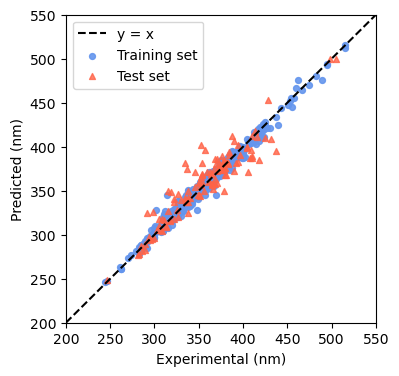

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4,4))
plt.plot([200, 550], [200, 550], 'k--', label = 'y = x')
plt.scatter(y_train, y_pred_train_best, alpha=0.9, label='Training set', color='cornflowerblue', marker='o', s=18)  # Set color to cornflowerblue
plt.scatter(y_test, y_pred_test_best, alpha=0.8, label='Test set', color='tomato', marker='^', s=18)  # Set color to tomato
plt.xlim(200, 550)
plt.ylim(200, 550)
plt.legend()
plt.xlabel('Experimental (nm)')
plt.ylabel('Predicted (nm)')
plt.savefig('CATB-best.png',dpi=300, bbox_inches='tight')
plt.show()

In [26]:
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error, make_scorer

print('training R = %.3f' % np.sqrt(r2_score(y_train, best_catb.predict(X_train))))
print('training R2 = %.3f' % r2_score(y_train, best_catb.predict(X_train)))
print('training RMSE = %.3f' % np.sqrt(mean_squared_error(y_train, best_catb.predict(X_train))))
print('training MAE = %.3f' %mean_absolute_error(y_train, best_catb.predict(X_train)))

print('test R = %.3f' % np.sqrt(r2_score(y_test, best_catb.predict(X_test))))
print('test R2 = %.3f' % r2_score(y_test, best_catb.predict(X_test)))
print('test RMSE = %.3f' % np.sqrt(mean_squared_error(y_test, best_catb.predict(X_test))))
print('training MAE = %.3f' %mean_absolute_error(y_test, best_catb.predict(X_test)))

training R = 0.992
training R2 = 0.984
training RMSE = 5.109
training MAE = 3.722
test R = 0.935
test R2 = 0.874
test RMSE = 15.006
training MAE = 10.570


In [9]:
from sklearn.model_selection import KFold, cross_val_score

crossvalidation = KFold(n_splits=10, shuffle=True, random_state=1)                        
r2_scores_catb = cross_val_score(best_catb, X_selected, y, scoring='r2', cv=crossvalidation)
rmse_scores_catb = cross_val_score(best_catb, X_selected,y, scoring='neg_root_mean_squared_error', cv=crossvalidation)
mae_scores_catb = cross_val_score(best_catb, X_selected, y, scoring=make_scorer(mean_absolute_error), cv=crossvalidation)

print('Cross-Validation Results:')
print('Folds:%i, mean R: %.3f' %(len(r2_scores_catb), np.sqrt(r2_scores_catb.mean())))
print('Folds:%i, mean R2: %.3f' %(len(r2_scores_catb), r2_scores_catb.mean()))
print('Folds:%i, mean RMSE: %.3f' %(len(rmse_scores_catb), -rmse_scores_catb.mean()))
print('Folds:%i, mean MAE: %.3f' %(len(mae_scores_catb), mae_scores_catb.mean()))

0:	learn: 39.6288213	total: 1.5ms	remaining: 1.35s
1:	learn: 37.6646977	total: 3.35ms	remaining: 1.5s
2:	learn: 36.0109088	total: 4.39ms	remaining: 1.31s
3:	learn: 34.3005491	total: 5.56ms	remaining: 1.24s
4:	learn: 32.9399523	total: 6.87ms	remaining: 1.23s
5:	learn: 31.7115789	total: 8.19ms	remaining: 1.22s
6:	learn: 30.5031497	total: 9.44ms	remaining: 1.2s
7:	learn: 29.4398592	total: 10.9ms	remaining: 1.21s
8:	learn: 28.5375190	total: 12ms	remaining: 1.18s
9:	learn: 27.6713381	total: 13.1ms	remaining: 1.17s
10:	learn: 26.9777456	total: 14.2ms	remaining: 1.15s
11:	learn: 26.3566698	total: 15.3ms	remaining: 1.14s
12:	learn: 25.7394854	total: 16.6ms	remaining: 1.13s
13:	learn: 25.1258480	total: 17.7ms	remaining: 1.12s
14:	learn: 24.6849773	total: 18.8ms	remaining: 1.11s
15:	learn: 24.2699205	total: 20ms	remaining: 1.11s
16:	learn: 23.7705797	total: 21.2ms	remaining: 1.1s
17:	learn: 23.3007844	total: 22.4ms	remaining: 1.09s
18:	learn: 22.8439973	total: 23.5ms	remaining: 1.09s
19:	learn: 

167:	learn: 11.0490664	total: 181ms	remaining: 788ms
168:	learn: 10.9843129	total: 182ms	remaining: 787ms
169:	learn: 10.9461028	total: 183ms	remaining: 786ms
170:	learn: 10.9260645	total: 184ms	remaining: 785ms
171:	learn: 10.9193821	total: 185ms	remaining: 784ms
172:	learn: 10.8832454	total: 186ms	remaining: 782ms
173:	learn: 10.8791859	total: 187ms	remaining: 781ms
174:	learn: 10.8365059	total: 188ms	remaining: 779ms
175:	learn: 10.8240954	total: 189ms	remaining: 778ms
176:	learn: 10.7891067	total: 190ms	remaining: 777ms
177:	learn: 10.7587383	total: 191ms	remaining: 776ms
178:	learn: 10.7542085	total: 192ms	remaining: 775ms
179:	learn: 10.7182603	total: 194ms	remaining: 774ms
180:	learn: 10.6661505	total: 195ms	remaining: 775ms
181:	learn: 10.6232982	total: 196ms	remaining: 773ms
182:	learn: 10.5805038	total: 197ms	remaining: 772ms
183:	learn: 10.5531556	total: 198ms	remaining: 770ms
184:	learn: 10.5447800	total: 199ms	remaining: 770ms
185:	learn: 10.5188421	total: 200ms	remaining:

330:	learn: 7.9174279	total: 349ms	remaining: 600ms
331:	learn: 7.9163017	total: 350ms	remaining: 599ms
332:	learn: 7.8950818	total: 352ms	remaining: 599ms
333:	learn: 7.8810693	total: 353ms	remaining: 598ms
334:	learn: 7.8614287	total: 354ms	remaining: 597ms
335:	learn: 7.8436018	total: 355ms	remaining: 596ms
336:	learn: 7.8291864	total: 356ms	remaining: 595ms
337:	learn: 7.8200671	total: 357ms	remaining: 594ms
338:	learn: 7.8058138	total: 358ms	remaining: 593ms
339:	learn: 7.8031506	total: 359ms	remaining: 592ms
340:	learn: 7.7794788	total: 360ms	remaining: 590ms
341:	learn: 7.7570698	total: 361ms	remaining: 589ms
342:	learn: 7.7488231	total: 362ms	remaining: 588ms
343:	learn: 7.7290079	total: 365ms	remaining: 589ms
344:	learn: 7.7215971	total: 366ms	remaining: 588ms
345:	learn: 7.7123275	total: 367ms	remaining: 587ms
346:	learn: 7.6949349	total: 368ms	remaining: 586ms
347:	learn: 7.6807110	total: 369ms	remaining: 585ms
348:	learn: 7.6607141	total: 370ms	remaining: 584ms
349:	learn: 

507:	learn: 6.0980798	total: 525ms	remaining: 405ms
508:	learn: 6.0908146	total: 526ms	remaining: 404ms
509:	learn: 6.0809247	total: 527ms	remaining: 403ms
510:	learn: 6.0739699	total: 528ms	remaining: 402ms
511:	learn: 6.0644882	total: 530ms	remaining: 401ms
512:	learn: 6.0560006	total: 531ms	remaining: 400ms
513:	learn: 6.0440675	total: 532ms	remaining: 399ms
514:	learn: 6.0381163	total: 533ms	remaining: 398ms
515:	learn: 6.0336667	total: 534ms	remaining: 397ms
516:	learn: 6.0258600	total: 535ms	remaining: 396ms
517:	learn: 6.0082192	total: 536ms	remaining: 395ms
518:	learn: 6.0051566	total: 538ms	remaining: 395ms
519:	learn: 5.9967612	total: 539ms	remaining: 394ms
520:	learn: 5.9934567	total: 541ms	remaining: 393ms
521:	learn: 5.9858279	total: 542ms	remaining: 392ms
522:	learn: 5.9750649	total: 543ms	remaining: 391ms
523:	learn: 5.9711781	total: 544ms	remaining: 390ms
524:	learn: 5.9648544	total: 545ms	remaining: 389ms
525:	learn: 5.9575287	total: 546ms	remaining: 388ms
526:	learn: 

677:	learn: 5.0114878	total: 693ms	remaining: 227ms
678:	learn: 5.0024141	total: 694ms	remaining: 226ms
679:	learn: 5.0002423	total: 695ms	remaining: 225ms
680:	learn: 4.9889848	total: 697ms	remaining: 224ms
681:	learn: 4.9818375	total: 698ms	remaining: 223ms
682:	learn: 4.9768028	total: 699ms	remaining: 222ms
683:	learn: 4.9733077	total: 700ms	remaining: 221ms
684:	learn: 4.9671493	total: 701ms	remaining: 220ms
685:	learn: 4.9587046	total: 702ms	remaining: 219ms
686:	learn: 4.9521713	total: 703ms	remaining: 218ms
687:	learn: 4.9405707	total: 704ms	remaining: 217ms
688:	learn: 4.9312960	total: 705ms	remaining: 216ms
689:	learn: 4.9251789	total: 708ms	remaining: 215ms
690:	learn: 4.9202779	total: 709ms	remaining: 214ms
691:	learn: 4.9154638	total: 710ms	remaining: 213ms
692:	learn: 4.9099236	total: 711ms	remaining: 212ms
693:	learn: 4.9095301	total: 712ms	remaining: 211ms
694:	learn: 4.9051123	total: 713ms	remaining: 210ms
695:	learn: 4.8977149	total: 714ms	remaining: 209ms
696:	learn: 

842:	learn: 4.3053126	total: 862ms	remaining: 58.3ms
843:	learn: 4.2984206	total: 863ms	remaining: 57.3ms
844:	learn: 4.2965178	total: 864ms	remaining: 56.2ms
845:	learn: 4.2958722	total: 865ms	remaining: 55.2ms
846:	learn: 4.2934822	total: 866ms	remaining: 54.2ms
847:	learn: 4.2884937	total: 867ms	remaining: 53.2ms
848:	learn: 4.2880961	total: 868ms	remaining: 52.2ms
849:	learn: 4.2863254	total: 869ms	remaining: 51.1ms
850:	learn: 4.2846338	total: 870ms	remaining: 50.1ms
851:	learn: 4.2824864	total: 871ms	remaining: 49.1ms
852:	learn: 4.2818607	total: 872ms	remaining: 48.1ms
853:	learn: 4.2811136	total: 873ms	remaining: 47ms
854:	learn: 4.2766945	total: 875ms	remaining: 46.1ms
855:	learn: 4.2726548	total: 876ms	remaining: 45.1ms
856:	learn: 4.2721041	total: 878ms	remaining: 44ms
857:	learn: 4.2684807	total: 879ms	remaining: 43ms
858:	learn: 4.2625282	total: 880ms	remaining: 42ms
859:	learn: 4.2579871	total: 880ms	remaining: 41ms
860:	learn: 4.2523104	total: 881ms	remaining: 39.9ms
861

... (130 outputs left out)

386:	learn: 7.5905018	total: 419ms	remaining: 555ms
387:	learn: 7.5831503	total: 420ms	remaining: 554ms
388:	learn: 7.5772056	total: 421ms	remaining: 553ms
389:	learn: 7.5621345	total: 422ms	remaining: 552ms
390:	learn: 7.5609965	total: 423ms	remaining: 551ms
391:	learn: 7.5544035	total: 424ms	remaining: 550ms
392:	learn: 7.5413319	total: 425ms	remaining: 549ms
393:	learn: 7.5409602	total: 426ms	remaining: 547ms
394:	learn: 7.5328864	total: 427ms	remaining: 546ms
395:	learn: 7.5214766	total: 428ms	remaining: 545ms
396:	learn: 7.5134353	total: 429ms	remaining: 544ms
397:	learn: 7.5054306	total: 430ms	remaining: 542ms
398:	learn: 7.4886631	total: 431ms	remaining: 541ms
399:	learn: 7.4759249	total: 432ms	remaining: 540ms
400:	learn: 7.4409175	total: 433ms	remaining: 539ms
401:	learn: 7.4357475	total: 434ms	remaining: 537ms
402:	learn: 7.4226521	total: 435ms	remaining: 536ms
403:	learn: 7.4050615	total: 436ms	remaining: 535ms
404:	learn: 7.3941401	total: 438ms	remaining: 536ms
405:	learn: 

558:	learn: 6.0074436	total: 588ms	remaining: 359ms
559:	learn: 5.9996250	total: 590ms	remaining: 358ms
560:	learn: 5.9958973	total: 591ms	remaining: 357ms
561:	learn: 5.9933877	total: 592ms	remaining: 356ms
562:	learn: 5.9827738	total: 593ms	remaining: 355ms
563:	learn: 5.9741800	total: 594ms	remaining: 354ms
564:	learn: 5.9688497	total: 595ms	remaining: 353ms
565:	learn: 5.9589403	total: 596ms	remaining: 352ms
566:	learn: 5.9565255	total: 597ms	remaining: 350ms
567:	learn: 5.9459474	total: 598ms	remaining: 349ms
568:	learn: 5.9383788	total: 599ms	remaining: 348ms
569:	learn: 5.9373744	total: 600ms	remaining: 347ms
570:	learn: 5.9337817	total: 602ms	remaining: 347ms
571:	learn: 5.9311850	total: 603ms	remaining: 346ms
572:	learn: 5.9252034	total: 605ms	remaining: 345ms
573:	learn: 5.9178801	total: 607ms	remaining: 345ms
574:	learn: 5.9168364	total: 608ms	remaining: 343ms
575:	learn: 5.9155580	total: 609ms	remaining: 342ms
576:	learn: 5.9146158	total: 610ms	remaining: 341ms
577:	learn: 

729:	learn: 5.0676944	total: 758ms	remaining: 176ms
730:	learn: 5.0600085	total: 759ms	remaining: 175ms
731:	learn: 5.0572403	total: 760ms	remaining: 174ms
732:	learn: 5.0531674	total: 761ms	remaining: 173ms
733:	learn: 5.0486046	total: 762ms	remaining: 172ms
734:	learn: 5.0438221	total: 764ms	remaining: 171ms
735:	learn: 5.0370925	total: 765ms	remaining: 170ms
736:	learn: 5.0345670	total: 766ms	remaining: 169ms
737:	learn: 5.0248486	total: 767ms	remaining: 168ms
738:	learn: 5.0211551	total: 768ms	remaining: 167ms
739:	learn: 5.0182993	total: 769ms	remaining: 166ms
740:	learn: 5.0136477	total: 770ms	remaining: 165ms
741:	learn: 5.0094827	total: 771ms	remaining: 164ms
742:	learn: 5.0037412	total: 772ms	remaining: 163ms
743:	learn: 5.0010442	total: 773ms	remaining: 162ms
744:	learn: 4.9979068	total: 775ms	remaining: 161ms
745:	learn: 4.9947152	total: 777ms	remaining: 160ms
746:	learn: 4.9916960	total: 778ms	remaining: 159ms
747:	learn: 4.9811501	total: 779ms	remaining: 158ms
748:	learn: 

893:	learn: 4.4957607	total: 925ms	remaining: 6.21ms
894:	learn: 4.4930155	total: 926ms	remaining: 5.17ms
895:	learn: 4.4928279	total: 927ms	remaining: 4.14ms
896:	learn: 4.4925180	total: 928ms	remaining: 3.1ms
897:	learn: 4.4922446	total: 929ms	remaining: 2.07ms
898:	learn: 4.4905664	total: 930ms	remaining: 1.03ms
899:	learn: 4.4879765	total: 931ms	remaining: 0us
Cross-Validation Results:
Folds:10, mean R: 0.911
Folds:10, mean R2: 0.830
Folds:10, mean RMSE: 16.162
Folds:10, mean MAE: 11.836


In [10]:
std_error_r = np.std(np.sqrt(r2_scores_catb))
print("R的误差范围：%.3f" %(std_error_r))
std_error_r2 = np.std(r2_scores_catb)
print("R2的误差范围：%.3f" %(std_error_r2))
std_error_rmse = np.std(rmse_scores_catb)
print("RMSE的误差范围：%.3f" %(std_error_rmse))
std_error_mae = np.std(mae_scores_catb)
print("MAE的误差范围：%.3f" %(std_error_mae))

R的误差范围：0.044
R2的误差范围：0.077
RMSE的误差范围：2.577
MAE的误差范围：1.693


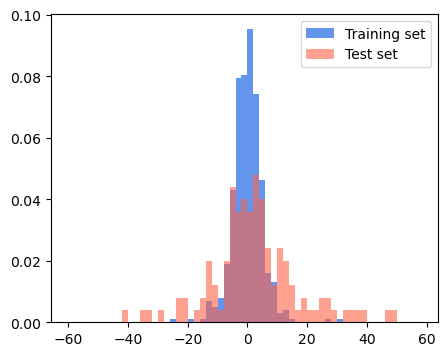

In [12]:
plt.figure(figsize=(5, 4))
plt.hist(best_catb.predict(X_train)-y_train, color='cornflowerblue',
         bins=np.arange(-60, 60, 2), density=True, label= 'Training set' )
plt.hist(best_catb.predict(X_test)-y_test, color='tomato',
         bins=np.arange(-60, 60, 2), density=True, alpha=0.6, label= 'Test set' )
plt.legend()
plt.savefig('CATB-error_distribution.png',dpi=300, bbox_inches='tight')
plt.show()